In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.append(str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from src.data import clean_download, compute_losses, check_prices
from src.risk_measures import hs_var_es
prices = clean_download("^GSPC", "2015-01-01", "2026-10-01")
print(check_prices(prices))
loss = compute_losses(prices)

{'missing': np.int64(0), 'non_positive': np.int64(0), 'high_below_low': np.int64(0), 'close_outside_range': np.int64(0), 'zero_range': np.int64(0), 'duplicate_dates': np.int64(0), 'unsorted': 0}


In [2]:
risk = hs_var_es(loss)
print(risk.dropna().head())
print(risk.dropna().describe())

                 var        es
Date                          
2015-12-31  0.028052  0.034201
2016-01-04  0.028052  0.034201
2016-01-05  0.028052  0.034201
2016-01-06  0.028052  0.034201
2016-01-07  0.028052  0.034201
               var           es
count  2702.000000  2702.000000
mean      0.029717     0.038485
std       0.014238     0.022148
min       0.013554     0.015873
25%       0.020110     0.025881
50%       0.027102     0.033277
75%       0.032631     0.041658
max       0.070064     0.102202


In [3]:
risk = hs_var_es(loss)
bt = risk.join(loss).dropna()

In [4]:
hit = bt['loss'] > bt['var']
print(f'Days tested: {hit.index.size}')
print(f'Violations: {hit.sum()}')
print(f'Violation rate: {hit.mean()}')
print(f"Expected number of violations: {0.01 * hit.index.size}")

Days tested: 2702
Violations: 43
Violation rate: 0.015914137675795706
Expected number of violations: 27.02


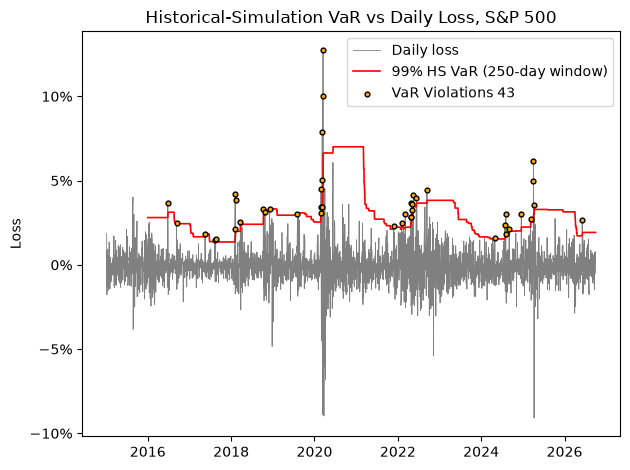

In [5]:
fig, ax = plt.subplots()
ax.plot(loss, label="Daily loss", color="grey", linewidth=0.6)
ax.plot(risk["var"], label="99% HS VaR (250-day window)", color="red", linewidth=1.2)
ax.scatter(bt.index[hit], bt['loss'][hit], color = 'orange', s = 12, zorder = 3, label = f'VaR Violations {hit.sum()}', edgecolors='black', linewidths=1)
ax.set_title("Historical-Simulation VaR vs Daily Loss, S&P 500")
ax.set_ylabel("Loss")
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.legend()

fig.tight_layout()
fig.savefig(ROOT / "results" / "hs_var.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
from src.backtests import kupiec_test
kupiec_test(hit)

{'n': 2702,
 'x': 43,
 'rate': 0.015914137675795706,
 'LR': 8.093212561062956,
 'p_value': 0.004443133540870654}

In [7]:
from src.backtests import christoffersen_independence
christoffersen_independence(hit)

{'n00': 2620,
 'n01': 38,
 'n10': 38,
 'n11': 5,
 'pi01': 0.014296463506395787,
 'pi11': 0.11627906976744186,
 'LR': 12.172135735552445,
 'p_value': 0.0004850873128836963}

In [8]:
from src.backtests import conditional_coverage
conditional_coverage(hit)

{'LR_unconditional': 8.093212561062956,
 'LR_independence': 12.172135735552445,
 'LR_conditional': 20.2653482966154,
 'p_value': 3.9759007120436866e-05}

In [9]:
from src.backtests import backtest_summary

backtest_summary(hit, 'HS')

,days,violations,expected,rate,LR_uc,p_uc,LR_ind,p_ind,LR_cc,p_cc
HS,2702,43,27.02,0.015914,8.093213,0.004443,12.172136,0.000485,20.265348,0.00004
